## Problema 1 - Regressão Linear Múltipla

### 1. Carregamento e exploração dos dados

In [4]:
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

dataset = fetch_ucirepo(id=294)

X = dataset.data.features
y = dataset.data.targets

df = pd.concat([X, y], axis=1)

display(df.head())

,AT,V,AP,RH,PE
0,14.96,41.76,1024.07,73.17,463.26
1,25.18,62.96,1020.04,59.08,444.37
2,5.11,39.40,1012.16,92.14,488.56
3,20.86,57.32,1010.24,76.64,446.48
4,10.82,37.50,1009.23,96.62,473.90


In [5]:
print("Dimensões:", df.shape)

print("\nInformações gerais:")
df.info()

print("\nValores ausentes:")
print(df.isnull().sum())

print("\nEstatísticas descritivas:")
display(df.describe())

Dimensões: (9568, 5)

Informações gerais:
<class 'pandas.DataFrame'>
RangeIndex: 9568 entries, 0 to 9567
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   AT      9568 non-null   float64
 1   V       9568 non-null   float64
 2   AP      9568 non-null   float64
 3   RH      9568 non-null   float64
 4   PE      9568 non-null   float64
dtypes: float64(5)
memory usage: 373.9 KB

Valores ausentes:
AT    0
V     0
AP    0
RH    0
PE    0
dtype: int64

Estatísticas descritivas:


,AT,V,AP,RH,PE
count,9568.000000,9568.000000,9568.000000,9568.000000,9568.000000
mean,19.651231,54.305804,1013.259078,73.308978,454.365009
std,7.452473,12.707893,5.938784,14.600269,17.066995
min,1.810000,25.360000,992.890000,25.560000,420.260000
25%,13.510000,41.740000,1009.100000,63.327500,439.750000
50%,20.345000,52.080000,1012.940000,74.975000,451.550000
75%,25.720000,66.540000,1017.260000,84.830000,468.430000
max,37.110000,81.560000,1033.300000,100.160000,495.760000


## 2. Análise de correlação

### 2.1. Correlação entre as variáveis independentes e PE

In [6]:
correlacao = df.corr(method="pearson")

correlacao_pe = correlacao["PE"].drop("PE")

correlacao_pe = correlacao_pe.sort_values(
    key=abs,
    ascending=False
)

display(correlacao_pe)

AT   -0.948128
V    -0.869780
AP    0.518429
RH    0.389794
Name: PE, dtype: float64

### 2.2. Correlação entre as variáveis independentes

In [7]:
variaveis = ["AT", "V", "AP", "RH"]

correlacao_independentes = df[variaveis].corr()

display(correlacao_independentes)

,AT,V,AP,RH
AT,1.000000,0.844107,-0.507549,-0.542535
V,0.844107,1.000000,-0.413502,-0.312187
AP,-0.507549,-0.413502,1.000000,0.099574
RH,-0.542535,-0.312187,0.099574,1.000000


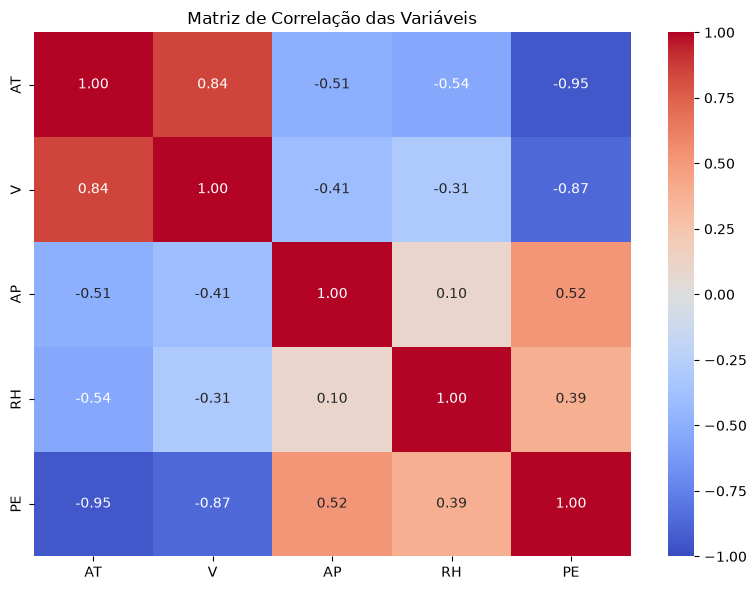

In [8]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    correlacao,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Matriz de Correlação das Variáveis")
plt.tight_layout()
plt.show()